<a href="https://colab.research.google.com/github/uhyeon1222-bit/work/blob/main/%EC%93%B0%EB%A0%88%EA%B8%B0_%EC%9D%B4%EB%AF%B8%EC%A7%80_%EB%B6%84%EB%A5%98_5756254_%EA%B9%80%EC%9A%B0%ED%98%84.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Cell 1: 환경 설정 및 캐글 데이터셋 다운로드

In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from collections import Counter

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.model_selection import StratifiedShuffleSplit
from sklearn.metrics import classification_report, confusion_matrix

import kagglehub

# 1. 재현성을 위한 시드(Seed) 고정
def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True

seed_everything(42)

# GPU 확인
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"사용 중인 디바이스: {device}")

# 2. 캐글 데이터셋 다운로드
path = kagglehub.dataset_download("mostafaabla/garbage-classification")
data_dir = os.path.join(path, "garbage_classification")
print("데이터셋 경로:", data_dir)

사용 중인 디바이스: cuda
Using Colab cache for faster access to the 'garbage-classification' dataset.
데이터셋 경로: /kaggle/input/garbage-classification/garbage_classification


## Cell 2: 데이터 탐색 (EDA) 및 분포 그래프 생성

총 클래스 개수 (12개): ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']
총 이미지 개수: 15515장


/tmp/ipykernel_334/2116006816.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=counts_df, x='Class', y='Count', palette='viridis')


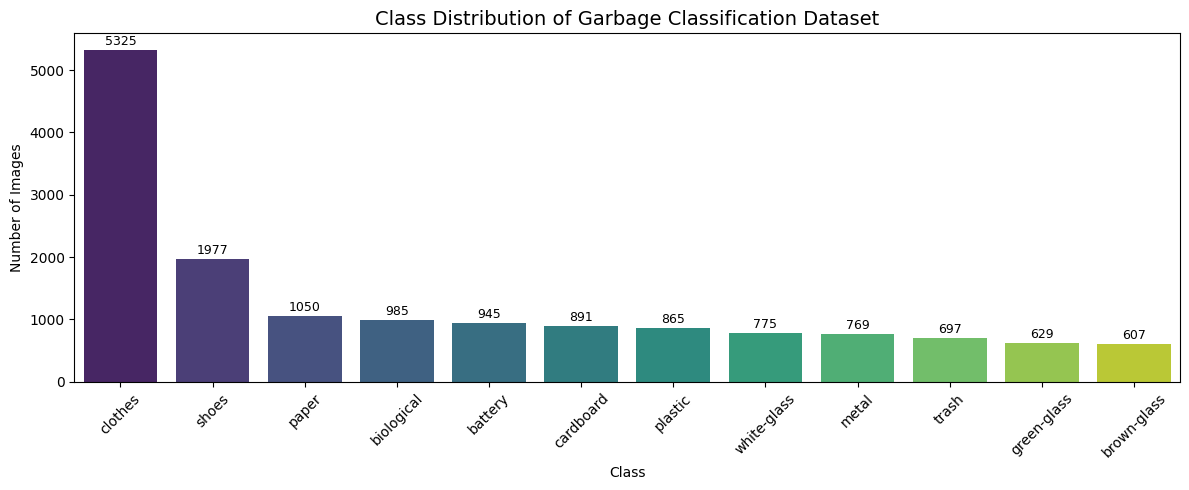

In [2]:
# 전체 데이터셋 로드
raw_dataset = datasets.ImageFolder(root=data_dir)
class_names = raw_dataset.classes
num_classes = len(class_names)
print(f"총 클래스 개수 ({num_classes}개): {class_names}")
print(f"총 이미지 개수: {len(raw_dataset)}장")

# 클래스별 이미지 개수 카운트
targets = raw_dataset.targets
class_counts = Counter(targets)
counts_df = pd.DataFrame({
    'Class': [class_names[i] for i in range(num_classes)],
    'Count': [class_counts[i] for i in range(num_classes)]
}).sort_values(by='Count', ascending=False)

# 막대그래프 시각화
plt.figure(figsize=(12, 5))
sns.barplot(data=counts_df, x='Class', y='Count', palette='viridis')
plt.title('Class Distribution of Garbage Classification Dataset', fontsize=14)
plt.xticks(rotation=45)
plt.ylabel('Number of Images')
for idx, row in enumerate(counts_df.itertuples()):
    plt.text(idx, row.Count + 80, str(row.Count), ha='center', fontsize=9)
plt.tight_layout()
plt.savefig('eda_class_distribution.png', dpi=300)
plt.show()

## Cell 3: 데이터 분할 및 AI 이미지 대응용 데이터 증강 (Data Augmentation)

In [7]:
# 하이퍼파라미터 딕셔너리
CONFIG = {
    "model_name": "CustomGarbageCNN",
    "img_size": 224,
    "batch_size": 32,
    "epochs": 20,
    "lr": 1e-4,
    "weight_decay": 1e-2,
    "dropout": 0.3,
    "use_augmentation": True,
    "use_class_weights": True
}

# ImageNet 표준 정규화 값
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]

# 학습용 전처리
if CONFIG["use_augmentation"]:
    train_transform = transforms.Compose([
        transforms.RandomResizedCrop(CONFIG["img_size"], scale=(0.7, 1.0)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomRotation(degrees=20),
        # AI 생성 이미지의 과장된 색감/조명 변화 대응
        transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.1),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD)
    ])
else:
    # 과적합 비교 실험(Baseline)을 위한 무증강 전처리
    train_transform = transforms.Compose([
        transforms.Resize((CONFIG["img_size"], CONFIG["img_size"])),
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD)
    ])

# 검증 및 테스트용 전처리
val_transform = transforms.Compose([
    transforms.Resize((CONFIG["img_size"], CONFIG["img_size"])),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)
])

# Stratified Split (클래스 비율을 유지하며 8:2로 학습/검증 분할)
sss = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, val_idx = next(sss.split(np.zeros(len(targets)), targets))

train_full = datasets.ImageFolder(root=data_dir, transform=train_transform)
val_full = datasets.ImageFolder(root=data_dir, transform=val_transform)

train_dataset = Subset(train_full, train_idx)
val_dataset = Subset(val_full, val_idx)

train_loader = DataLoader(train_dataset, batch_size=CONFIG["batch_size"], shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=CONFIG["batch_size"], shuffle=False, num_workers=2, pin_memory=True)

print(f"학습 데이터: {len(train_dataset)}장 | 검증 데이터: {len(val_dataset)}장")

학습 데이터: 12412장 | 검증 데이터: 3103장


## Cell 4: 모델 정의

In [8]:
class ResidualBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv2d(out_ch, out_ch, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)

        self.shortcut = nn.Sequential()
        if stride != 1 or in_ch != out_ch:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_ch)
            )

    def forward(self, x):
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out += self.shortcut(x)
        return self.relu(out)

class CustomGarbageCNN(nn.Module):
    def __init__(self, num_classes=12, dropout_rate=0.3):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=2, padding=1, bias=False), # 224 -> 112
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1) # 112 -> 56
        )
        self.layer1 = self._make_layer(32, 64, num_blocks=2, stride=1)   # 56x56
        self.layer2 = self._make_layer(64, 128, num_blocks=2, stride=2)  # 28x28
        self.layer3 = self._make_layer(128, 256, num_blocks=2, stride=2) # 14x14
        self.layer4 = self._make_layer(256, 512, num_blocks=2, stride=2) # 7x7

        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(dropout_rate),
            nn.Linear(512, num_classes)
        )

    def _make_layer(self, in_ch, out_ch, num_blocks, stride):
        layers = [ResidualBlock(in_ch, out_ch, stride)]
        for _ in range(1, num_blocks):
            layers.append(ResidualBlock(out_ch, out_ch, stride=1))
        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.stem(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.pool(x)
        return self.classifier(x)

# 모델 생성 및 GPU 할당
model = CustomGarbageCNN(num_classes=num_classes, dropout_rate=CONFIG["dropout"]).to(device)

# 클래스 불균형 해소를 위한 가중치 계산 (기존 코드와 동일)
if CONFIG["use_class_weights"]:
    train_targets = [targets[i] for i in train_idx]
    class_sample_counts = np.array([train_targets.count(i) for i in range(num_classes)])
    weights = 1. / np.sqrt(class_sample_counts) # 완화된 역빈도 가중치
    weights = weights / weights.sum() * num_classes
    class_weights = torch.FloatTensor(weights).to(device)
    criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.1)
else:
    criterion = nn.CrossEntropyLoss()

# 옵티마이저 및 스케줄러 (사전학습 가중치가 없으므로 lr=1e-3 권장)
optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=CONFIG["weight_decay"])
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=CONFIG["epochs"], eta_min=1e-5)

## Cell 5: 학습 루프 및 최고 성능 모델 저장

In [10]:
best_val_acc = 0.0
history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

for epoch in range(CONFIG['epochs']):
    # 1) 학습 (Train)
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    train_loss = running_loss / total
    train_acc = 100. * correct / total

    # 2) 검증 (Validation)
    model.eval()
    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)
            _, predicted = outputs.max(1)
            val_total += labels.size(0)
            val_correct += predicted.eq(labels).sum().item()

    val_loss = val_running_loss / val_total
    val_acc = 100. * val_correct / val_total

    scheduler.step()

    history['train_loss'].append(train_loss)
    history['train_acc'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_acc'].append(val_acc)

    # 최고 성능 모델 저장 (파일명을 weights.pt로 고정)
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), "weights.pt")
        save_msg = "--> [Best Model Saved: weights.pt]"
    else:
        save_msg = ""

    print(f"Epoch [{epoch+1:02d}/{CONFIG['epochs']:02d}] "
          f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}% | "
          f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.2f}% {save_msg}")

print(f"\n학습 완료! 최고 검증 정확도: {best_val_acc:.2f}%")

Epoch [01/20] Train Loss: 2.0167 | Train Acc: 44.02% | Val Loss: 1.7732 | Val Acc: 54.46% --> [Best Model Saved: weights.pt]
Epoch [02/20] Train Loss: 1.8786 | Train Acc: 50.27% | Val Loss: 1.7453 | Val Acc: 54.91% --> [Best Model Saved: weights.pt]
Epoch [03/20] Train Loss: 1.7948 | Train Acc: 53.21% | Val Loss: 1.8107 | Val Acc: 51.11% 
Epoch [04/20] Train Loss: 1.7368 | Train Acc: 56.48% | Val Loss: 1.6412 | Val Acc: 59.59% --> [Best Model Saved: weights.pt]
Epoch [05/20] Train Loss: 1.6674 | Train Acc: 59.27% | Val Loss: 1.5849 | Val Acc: 61.10% --> [Best Model Saved: weights.pt]
Epoch [06/20] Train Loss: 1.6151 | Train Acc: 61.50% | Val Loss: 1.5891 | Val Acc: 65.65% --> [Best Model Saved: weights.pt]
Epoch [07/20] Train Loss: 1.5652 | Train Acc: 63.68% | Val Loss: 1.6024 | Val Acc: 61.81% 
Epoch [08/20] Train Loss: 1.5146 | Train Acc: 66.23% | Val Loss: 1.4164 | Val Acc: 68.19% --> [Best Model Saved: weights.pt]
Epoch [09/20] Train Loss: 1.4599 | Train Acc: 68.59% | Val Loss: 1.3

## Cell 6: 학습 곡선 및 혼동 행렬 시각화

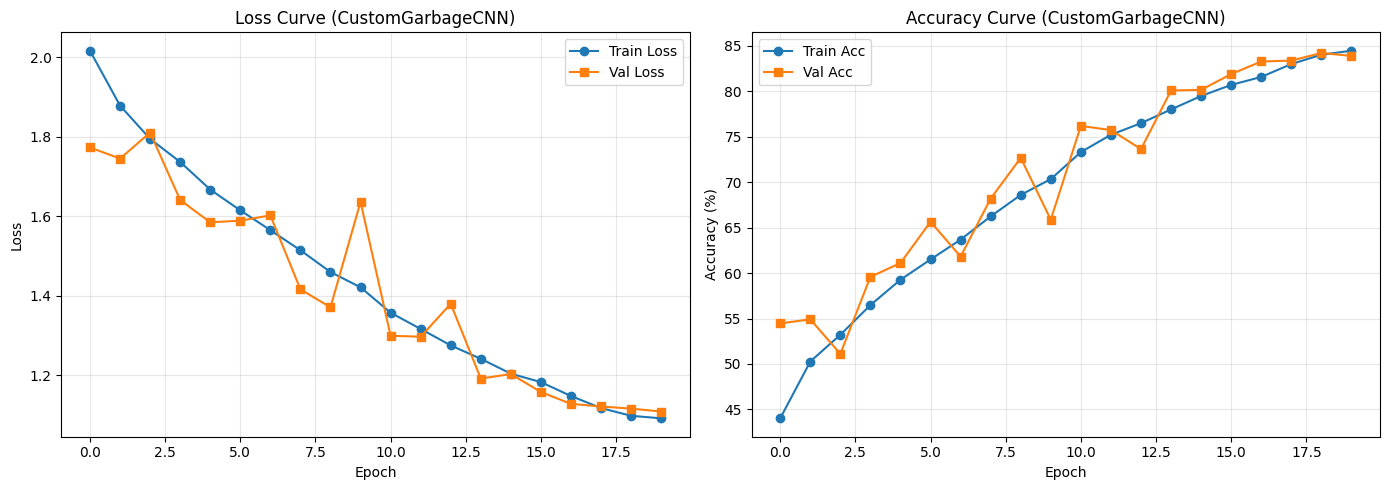


[분류 성능 리포트]
              precision    recall  f1-score   support

     battery     0.8497    0.7778    0.8122       189
  biological     0.8066    0.8680    0.8362       197
 brown-glass     0.7285    0.9016    0.8059       122
   cardboard     0.9000    0.7584    0.8232       178
     clothes     0.9564    0.9277    0.9418      1065
 green-glass     0.8531    0.9683    0.9071       126
       metal     0.6718    0.8506    0.7507       154
       paper     0.8392    0.7952    0.8166       210
     plastic     0.7039    0.7283    0.7159       173
       shoes     0.7955    0.8076    0.8015       395
       trash     0.8158    0.6691    0.7352       139
 white-glass     0.6797    0.6710    0.6753       155

    accuracy                         0.8421      3103
   macro avg     0.8000    0.8103    0.8018      3103
weighted avg     0.8473    0.8421    0.8427      3103



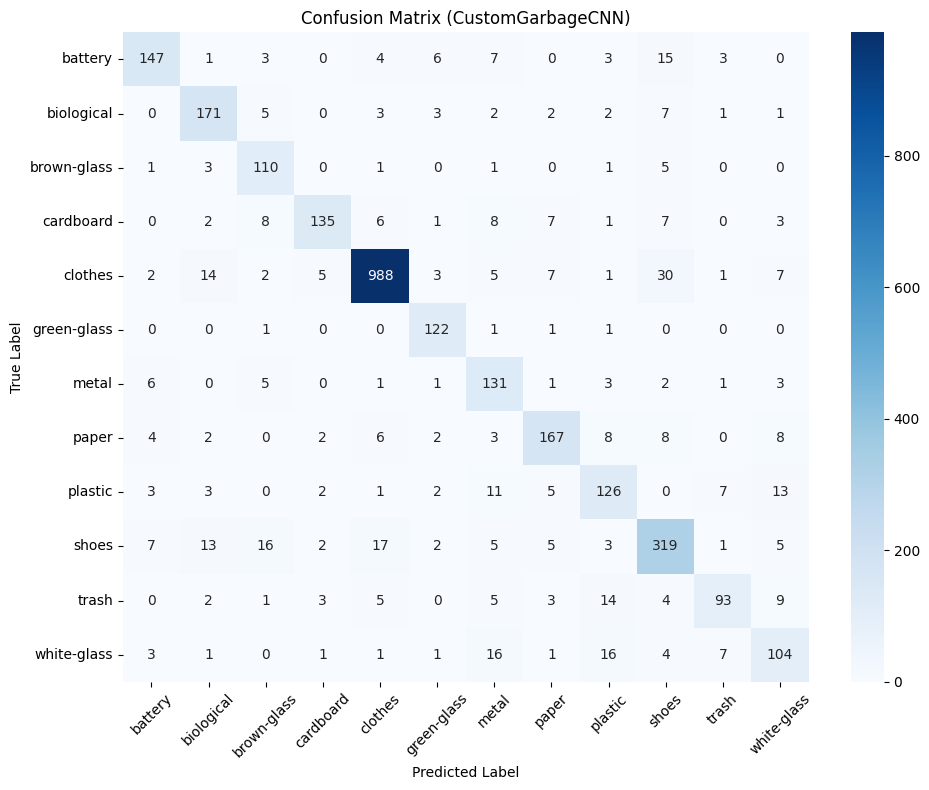

In [12]:
# 1. Loss & Accuracy 곡선
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history['train_loss'], label='Train Loss', marker='o')
axes[0].plot(history['val_loss'], label='Val Loss', marker='s')
axes[0].set_title(f"Loss Curve ({CONFIG['model_name']})")
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(history['train_acc'], label='Train Acc', marker='o')
axes[1].plot(history['val_acc'], label='Val Acc', marker='s')
axes[1].set_title(f"Accuracy Curve ({CONFIG['model_name']})")
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy (%)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(f"curve_{CONFIG['model_name']}.png", dpi=300)
plt.show()

# 2. Best 모델 로드 후 Confusion Matrix 출력
model.load_state_dict(torch.load("weights.pt"))
model.eval()

all_preds, all_labels = [], []
with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        outputs = model(images)
        _, preds = outputs.max(1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

print("\n[분류 성능 리포트]")
print(classification_report(all_labels, all_preds, target_names=class_names, digits=4))

cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title(f"Confusion Matrix ({CONFIG['model_name']})")
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(f"cm_{CONFIG['model_name']}.png", dpi=300)
plt.show()

In [13]:
%%writefile model.py
import torch
from torch import nn
from torchvision import transforms

CLASSES = [
    "battery", "biological", "brown-glass", "cardboard", "clothes", "green-glass",
    "metal", "paper", "plastic", "shoes", "trash", "white-glass",
]
IMG_SIZE = 224

class ResidualBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv2d(out_ch, out_ch, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)

        self.shortcut = nn.Sequential()
        if stride != 1 or in_ch != out_ch:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_ch)
            )

    def forward(self, x):
        out = self.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out += self.shortcut(x)
        return self.relu(out)

class CustomGarbageCNN(nn.Module):
    def __init__(self, num_classes=12):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1)
        )
        self.layer1 = self._make_layer(32, 64, num_blocks=2, stride=1)
        self.layer2 = self._make_layer(64, 128, num_blocks=2, stride=2)
        self.layer3 = self._make_layer(128, 256, num_blocks=2, stride=2)
        self.layer4 = self._make_layer(256, 512, num_blocks=2, stride=2)

        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(512, num_classes)
        )

    def _make_layer(self, in_ch, out_ch, num_blocks, stride):
        layers = [ResidualBlock(in_ch, out_ch, stride)]
        for _ in range(1, num_blocks):
            layers.append(ResidualBlock(out_ch, out_ch, stride=1))
        return nn.Sequential(*layers)

    def forward(self, x):
        x = self.stem(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.layer4(x)
        x = self.pool(x)
        return self.classifier(x)

def load_model(weights_path, device):
    model = CustomGarbageCNN(num_classes=len(CLASSES))
    state = torch.load(weights_path, map_location=device, weights_only=True)
    state = {k.removeprefix("module."): v for k, v in state.items()}
    model.load_state_dict(state)
    return model

def get_transform():
    return transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    ])

Writing model.py
